In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
! [ -e /content ] && pip install -Uqq fastbook
import fastbook
fastbook.setup_book()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 16.4 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.1/124.1 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.9/246.9 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 55.6 MB/s eta 0:00:00


In [4]:
from fastbook import *

In [5]:
from fastai.vision.all import *
path = untar_data(URLs.PETS)

<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 00:19&lt;00:00]</div>

In [6]:
Path.BASE_PATH = path

In [7]:
path.ls()

[Path('images'), Path('annotations')]

In [8]:
(path/"images").ls()

(#7393) [Path('images/beagle_115.jpg'), Path('images/boxer_18.jpg'), Path('images/Maine_Coon_157.jpg'), Path('images/scottish_terrier_28.jpg'), Path('images/english_setter_6.jpg'), Path('images/american_pit_bull_terrier_79.jpg'), Path('images/boxer_128.jpg'), Path('images/Persian_265.jpg'), Path('images/Maine_Coon_182.jpg'), Path('images/keeshond_89.jpg'), Path('images/chihuahua_82.jpg'), Path('images/basset_hound_5.jpg'), Path('images/english_cocker_spaniel_144.jpg'), Path('images/scottish_terrier_108.jpg'), Path('images/British_Shorthair_116.jpg'), Path('images/boxer_10.jpg'), Path('images/basset_hound_194.jpg'), Path('images/beagle_85.jpg'), Path('images/japanese_chin_87.jpg'), Path('images/pug_40.jpg'), Path('images/chihuahua_199.jpg'), Path('images/english_setter_152.jpg'), Path('images/Bengal_98.jpg'), Path('images/chihuahua_174.jpg'), Path('images/leonberger_166.jpg'), Path('images/german_shorthaired_68.jpg'), Path('images/miniature_pinscher_27.jpg'), Path('images/Ragdoll_257.jp

In [9]:
fname = (path/"images").ls()[0]

In [10]:
re.findall(r'(.+)_\d+.jpg$', fname.name)

['beagle']

In [11]:
pets = DataBlock(blocks = (ImageBlock, CategoryBlock),
                 get_items=get_image_files, 
                 splitter=RandomSplitter(seed=42),
                 get_y=using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), 'name'),
                 item_tfms=Resize(460),
                 batch_tfms=aug_transforms(size=224, min_scale=0.75))
dls = pets.dataloaders(path/"images")

In [12]:
item_tfms=Resize(460),
batch_tfms=aug_transforms(size=224, min_scale=0.75)

In [13]:
dblock1 = DataBlock(blocks=(ImageBlock(), CategoryBlock()),
                   get_y=parent_label,
                   item_tfms=Resize(460))

In [14]:
from fastdownload import download_url
download_url('https://github.com/fastai/fastbook/raw/master/images/grizzly.jpg', 'images/grizzly.jpg')

<div><progress max="697626" value="704512"></progress> 100.99% [704512/697626 00:00&lt;00:00]</div>

Path('images/grizzly.jpg')

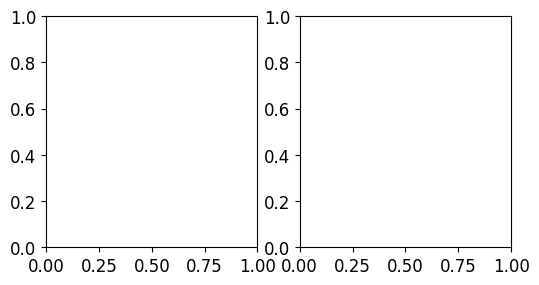

In [15]:
dls1 = dblock1.dataloaders([(Path.cwd()/'images'/'grizzly.jpg')]*100, bs=8)
dls1.train.get_idxs = lambda: Inf.ones
x,y = dls1.valid.one_batch()
_,axs = subplots(1, 2)

x1 = TensorImage(x.clone())
x1 = x1.affine_coord(sz=224)
x1 = x1.rotate(draw=30, p=1.)
x1 = x1.zoom(draw=1.2, p=1.)
x1 = x1.warp(draw_x=-0.2, draw_y=0.2, p=1.)

tfms = setup_aug_tfms([Rotate(draw=30, p=1, size=224), Zoom(draw=1.2, p=1., size=224),
                       Warp(draw_x=-0.2, draw_y=0.2, p=1., size=224)])
x = Pipeline(tfms)(x)

In [16]:
TensorImage(x[0]).show(ctx=axs[0])
TensorImage(x1[0]).show(ctx=axs[1]);

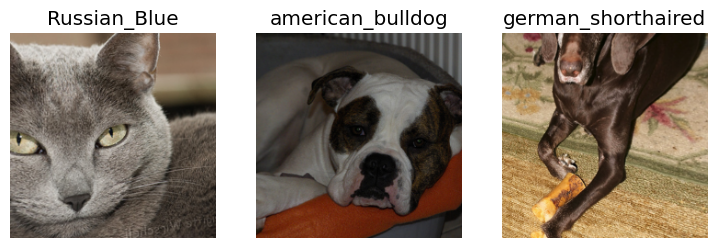

In [17]:
dls.show_batch(nrows=1, ncols=3)

In [18]:
pets1 = DataBlock(blocks = (ImageBlock, CategoryBlock),
                 get_items=get_image_files, 
                 splitter=RandomSplitter(seed=42),
                 get_y=using_attr(RegexLabeller(r'(.+)_\d+.jpg$'), 'name'),
                 item_tfms=Resize(460))
pets1.summary(path/"images")

Setting-up type transforms pipelines
Found 7390 items
2 datasets of sizes 5912,1478
Setting up Pipeline: PILBase.create
Setting up Pipeline: partial -> Categorize -- {'vocab': None, 'sort': True, 'add_na': False}


Building one sample
  Pipeline: PILBase.create
    starting from
      /root/.fastai/data/oxford-iiit-pet/images/basset_hound_43.jpg
    applying PILBase.create gives
      PILImage mode=RGB size=333x500
  Pipeline: partial -> Categorize -- {'vocab': None, 'sort': True, 'add_na': False}

    starting from
      /root/.fastai/data/oxford-iiit-pet/images/basset_hound_43.jpg
    applying partial gives
      basset_hound
    applying Categorize -- {'vocab': None, 'sort': True, 'add_na': False}
 gives
      TensorCategory(14)

Final sample: (PILImage mode=RGB size=333x500, TensorCategory(14))


Found 7390 items
2 datasets of sizes 5912,1478
Setting up Pipeline: PILBase.create
Setting up Pipeline: partial -> Categorize -- {'vocab': None, 'sort': True, 'add_na': False}

Setting up 

In [19]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(2)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 190MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.496423,0.385349,0.117050,00:35


epoch,train_loss,valid_loss,error_rate,time
0,0.493414,0.307459,0.098782,00:43
1,0.321746,0.220582,0.074425,00:46


In [20]:
x,y = dls.one_batch()

In [21]:
y

TensorCategory([27,  9,  8,  6,  2, 27,  9, 28, 26, 18, 19, 17, 12,  3, 21,  5, 20, 29, 22, 26, 15, 33,  8, 22, 25, 24, 11,  4, 21, 24, 21,  6, 22, 29,  7, 35, 16, 16,  1,  3, 25, 22,  7,  9, 29, 26,
                26, 30,  0, 29, 16,  1,  0, 18, 18, 36, 26, 18, 36, 35, 18, 28, 11,  9], device='cuda:0')

In [22]:
preds,_ = learn.get_preds(dl=[(x,y)])
preds[0]

tensor([1.2562e-10, 5.8699e-10, 5.6353e-09, 2.5237e-10, 8.2343e-09, 1.0752e-08, 6.1250e-08, 2.1787e-07, 2.5487e-10, 2.1433e-08, 9.0054e-10, 9.4773e-10, 3.9480e-10, 7.8747e-09, 1.1331e-07, 6.6162e-10,
        1.6598e-09, 1.4261e-09, 6.1703e-08, 2.7445e-09, 2.1076e-08, 2.8427e-07, 2.0438e-07, 2.7955e-07, 7.0344e-08, 4.5730e-06, 1.9451e-09, 9.9999e-01, 9.4068e-08, 3.7605e-10, 3.6919e-07, 2.0116e-08,
        1.6908e-08, 2.7540e-09, 2.0618e-09, 5.0584e-08, 6.7826e-09])

In [23]:
len(preds[0]),preds[0].sum()

(37, tensor(1.0000))

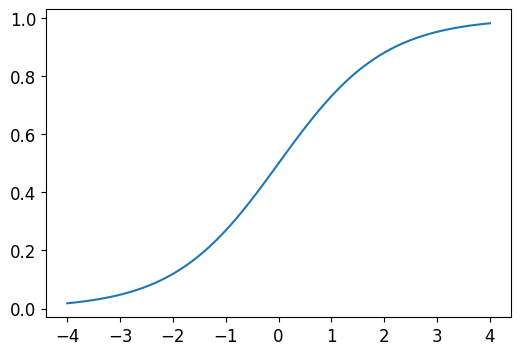

In [24]:
plot_function(torch.sigmoid, min=-4,max=4)

In [25]:
torch.random.manual_seed(42);

In [26]:
acts = torch.randn((6,2))*2
acts

tensor([[ 0.6734,  0.2576],
        [ 0.4689,  0.4607],
        [-2.2457, -0.3727],
        [ 4.4164, -1.2760],
        [ 0.9233,  0.5347],
        [ 1.0698,  1.6187]])

In [27]:
acts.sigmoid()

tensor([[0.6623, 0.5641],
        [0.6151, 0.6132],
        [0.0957, 0.4079],
        [0.9881, 0.2182],
        [0.7157, 0.6306],
        [0.7446, 0.8346]])

In [28]:
(acts[:,0]-acts[:,1]).sigmoid()

tensor([0.6025, 0.5021, 0.1332, 0.9966, 0.5959, 0.3661])

In [29]:
def softmax(x): return exp(x) / exp(x).sum(dim=1, keepdim=True)


In [30]:
sm_acts = torch.softmax(acts, dim=1)
sm_acts

tensor([[0.6025, 0.3975],
        [0.5021, 0.4979],
        [0.1332, 0.8668],
        [0.9966, 0.0034],
        [0.5959, 0.4041],
        [0.3661, 0.6339]])

In [31]:
def mnist_loss(inputs, targets):
    inputs = inputs.sigmoid()
    return torch.where(targets==1, 1-inputs, inputs).mean()

In [32]:
targ = tensor([0,1,0,1,1,0])

In [33]:
sm_acts

tensor([[0.6025, 0.3975],
        [0.5021, 0.4979],
        [0.1332, 0.8668],
        [0.9966, 0.0034],
        [0.5959, 0.4041],
        [0.3661, 0.6339]])

In [34]:
idx = range(6)
sm_acts[idx, targ]

tensor([0.6025, 0.4979, 0.1332, 0.0034, 0.4041, 0.3661])

In [35]:
from IPython.display import HTML
df = pd.DataFrame(sm_acts, columns=["3","7"])
df['targ'] = targ
df['idx'] = idx
df['result'] = sm_acts[range(6), targ]
t = df.style.hide(axis="index")

html = t._repr_html_().split('</style>')[1]
html = re.sub(r'<table id="([^"]+)"\s*>', r'<table >', html)
display(HTML(html))



3,7,targ,idx,result
0.602469,0.397531,0,0,0.602469
0.502065,0.497935,1,1,0.497935
0.133188,0.866811,0,2,0.133188
0.996640,0.003360,1,3,0.003360
0.595949,0.404051,1,4,0.404051
0.366118,0.633882,0,5,0.366118


In [36]:
-sm_acts[idx, targ]

tensor([-0.6025, -0.4979, -0.1332, -0.0034, -0.4041, -0.3661])

In [37]:
F.nll_loss(sm_acts, targ, reduction='none')

tensor([-0.6025, -0.4979, -0.1332, -0.0034, -0.4041, -0.3661])

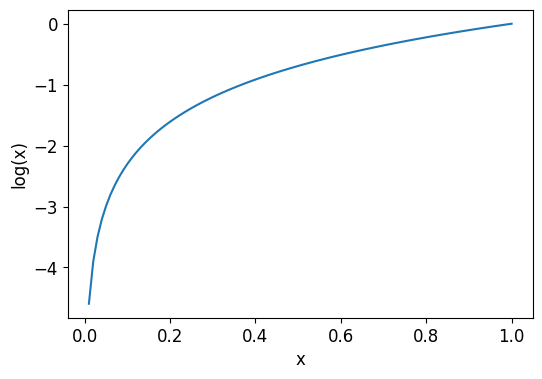

In [38]:
plot_function(torch.log, min=0,max=1, ty='log(x)', tx='x')

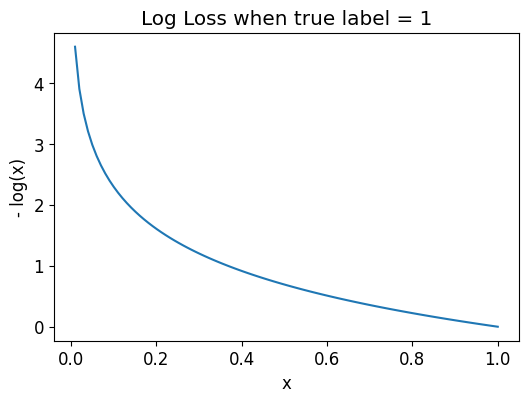

In [39]:
plot_function(lambda x: -1*torch.log(x), min=0,max=1, tx='x', ty='- log(x)', title = 'Log Loss when true label = 1')

In [40]:
from IPython.display import HTML
df['loss'] = -torch.log(tensor(df['result']))
t = df.style.hide()
html = t._repr_html_().split('</style>')[1]
html = re.sub(r'<table id="([^"]+)"\s*>', r'<table >', html)
display(HTML(html))

3,7,targ,idx,result,loss
0.602469,0.397531,0,0,0.602469,0.506720
0.502065,0.497935,1,1,0.497935,0.697285
0.133188,0.866811,0,2,0.133188,2.015990
0.996640,0.003360,1,3,0.003360,5.695763
0.595949,0.404051,1,4,0.404051,0.906213
0.366118,0.633882,0,5,0.366118,1.004798


In [41]:
loss_func = nn.CrossEntropyLoss()

In [42]:
loss_func(acts, targ)

tensor(1.8045)

In [43]:
F.cross_entropy(acts, targ)

tensor(1.8045)

In [44]:
nn.CrossEntropyLoss(reduction='none')(acts, targ)

tensor([0.5067, 0.6973, 2.0160, 5.6958, 0.9062, 1.0048])

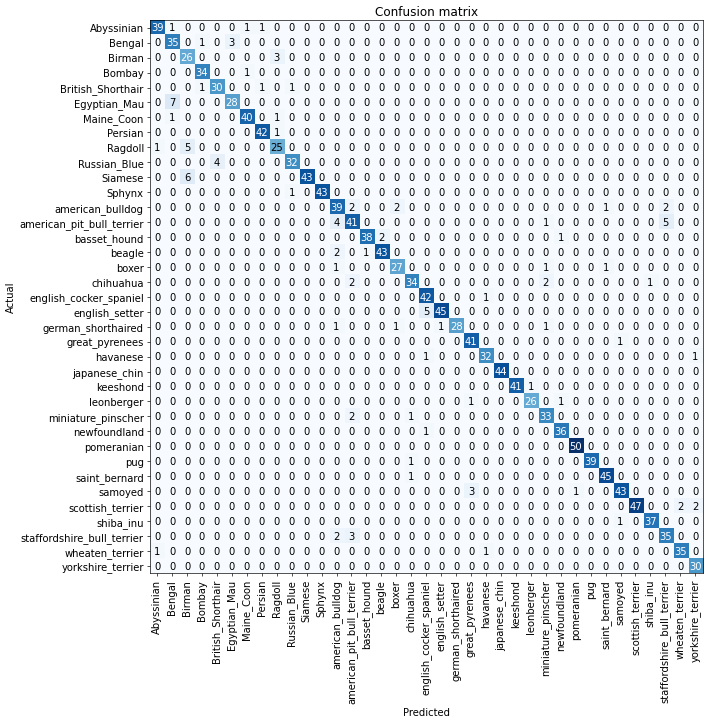

In [45]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix(figsize=(12,12), dpi=60)

In [46]:
interp.most_confused(min_val=5)

[('Egyptian_Mau', 'Bengal', np.int64(7)),
 ('Siamese', 'Birman', np.int64(6)),
 ('Ragdoll', 'Birman', np.int64(5)),
 ('american_pit_bull_terrier', 'staffordshire_bull_terrier', np.int64(5)),
 ('english_setter', 'english_cocker_spaniel', np.int64(5))]

In [47]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(1, base_lr=0.1)

epoch,train_loss,valid_loss,error_rate,time
0,2.618157,2.946807,0.365359,00:37


epoch,train_loss,valid_loss,error_rate,time
0,3.831880,2.568547,0.727334,00:46


<div></div>

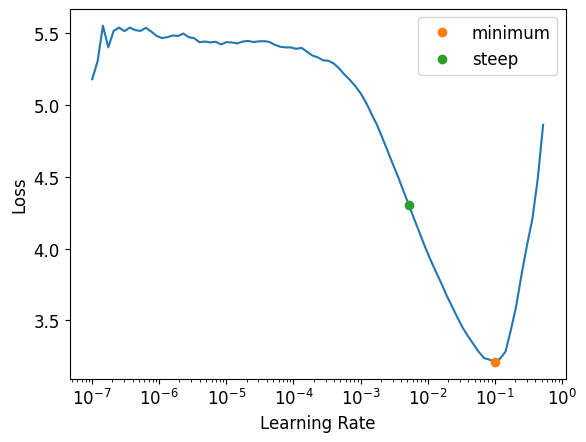

In [48]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
lr_min,lr_steep = learn.lr_find(suggest_funcs=(minimum, steep))

In [49]:
print(f"Minimum/10: {lr_min:.2e}, steepest point: {lr_steep:.2e}")

Minimum/10: 1.00e-02, steepest point: 5.25e-03


In [50]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(2, base_lr=3e-3)

epoch,train_loss,valid_loss,error_rate,time
0,1.304136,0.351246,0.111637,00:37


epoch,train_loss,valid_loss,error_rate,time
0,0.554857,0.351772,0.112314,00:47
1,0.337355,0.252483,0.076455,00:47


In [51]:
learn.fine_tune??

Signature:
learn.fine_tune(
    epochs,
    base_lr=0.002,
    freeze_epochs=1,
    lr_mult=100,
    pct_start=0.3,
    div=5.0,
    *,
    lr_max=None,
    div_final=100000.0,
    wd=None,
    moms=None,
    cbs=None,
    reset_opt=False,
    start_epoch=0,
)
Source:   
@patch
@delegates(Learner.fit_one_cycle)
def fine_tune(self:Learner, epochs, base_lr=2e-3, freeze_epochs=1, lr_mult=100,
              pct_start=0.3, div=5.0, **kwargs):
    "Fine tune with `Learner.freeze` for `freeze_epochs`, then with `Learner.unfreeze` for `epochs`, using discriminative LR."
    self.freeze()
    self.fit_one_cycle(freeze_epochs, slice(base_lr), pct_start=0.99, **kwargs)
    base_lr /= 2
    self.unfreeze()
    self.fit_one_cycle(epochs, slice(base_lr/lr_mult, base_lr), pct_start=pct_start, div=div, **kwargs)
File:      /usr/local/lib/python3.12/dist-packages/fastai/callback/schedule.py
Type:      method


In [52]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fit_one_cycle(3, 3e-3)

epoch,train_loss,valid_loss,error_rate,time
0,1.132518,0.322534,0.102165,00:37
1,0.553319,0.278937,0.092016,00:37
2,0.329012,0.248403,0.081191,00:38


In [53]:
learn.unfreeze()

<div></div>

SuggestedLRs(valley=1.737800812406931e-05)

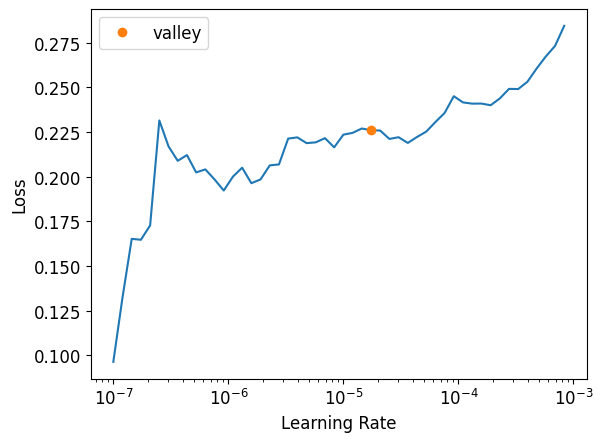

In [54]:
learn.lr_find()

In [57]:
learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fit_one_cycle(3, 3e-3)
learn.unfreeze()
learn.fit_one_cycle(12, lr_max=slice(1e-6,1e-4))

epoch,train_loss,valid_loss,error_rate,time
0,1.147202,0.354905,0.108931,00:41
1,0.525041,0.251922,0.080514,00:40
2,0.328706,0.223596,0.078484,00:40


epoch,train_loss,valid_loss,error_rate,time
0,0.262034,0.218709,0.073748,00:49
1,0.249568,0.210904,0.072395,00:49
2,0.238236,0.206023,0.068336,00:49
3,0.218140,0.204275,0.071042,00:49
4,0.189778,0.201021,0.068336,00:48
5,0.173384,0.200713,0.071042,00:49
6,0.167439,0.194215,0.063599,00:48
7,0.148179,0.200608,0.070365,00:47
8,0.145238,0.200142,0.069689,00:47
9,0.129624,0.195998,0.073748,00:46


In [58]:
learn.fit_one_cycle(6, lr_max=1e-5)

epoch,train_loss,valid_loss,error_rate,time
0,0.124809,0.197757,0.069012,00:47
1,0.124902,0.203189,0.067659,00:46
2,0.108698,0.202751,0.066982,00:47
3,0.108135,0.198485,0.064276,00:46
4,0.108432,0.200950,0.067659,00:47
5,0.102557,0.199435,0.064953,00:47


<Axes: title={'center': 'learning curve'}, xlabel='steps', ylabel='loss'>

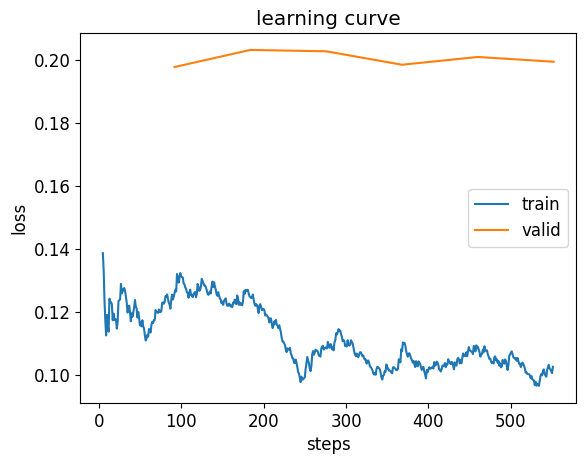

In [59]:
learn.recorder.plot_loss()

In [60]:
from fastai.callback.fp16 import *
learn = vision_learner(dls, resnet50, metrics=error_rate).to_fp16()
learn.fine_tune(6, freeze_epochs=3)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 217MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,2.207429,0.446866,0.131935,00:40
1,0.845982,0.339540,0.112991,00:39
2,0.536116,0.303349,0.094046,00:39


epoch,train_loss,valid_loss,error_rate,time
0,0.286791,0.237849,0.070365,00:45
1,0.253605,0.241860,0.078484,00:45
2,0.197898,0.236470,0.070365,00:45
3,0.134676,0.233863,0.064953,00:45
4,0.087480,0.195581,0.052774,00:45
5,0.070123,0.203834,0.057510,00:44
